In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from IPython.display import display
from ISLP import load_data, confusion_table
from ISLP.models import ModelSpec as MS, summarize
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA, QuadraticDiscriminantAnalysis as QDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

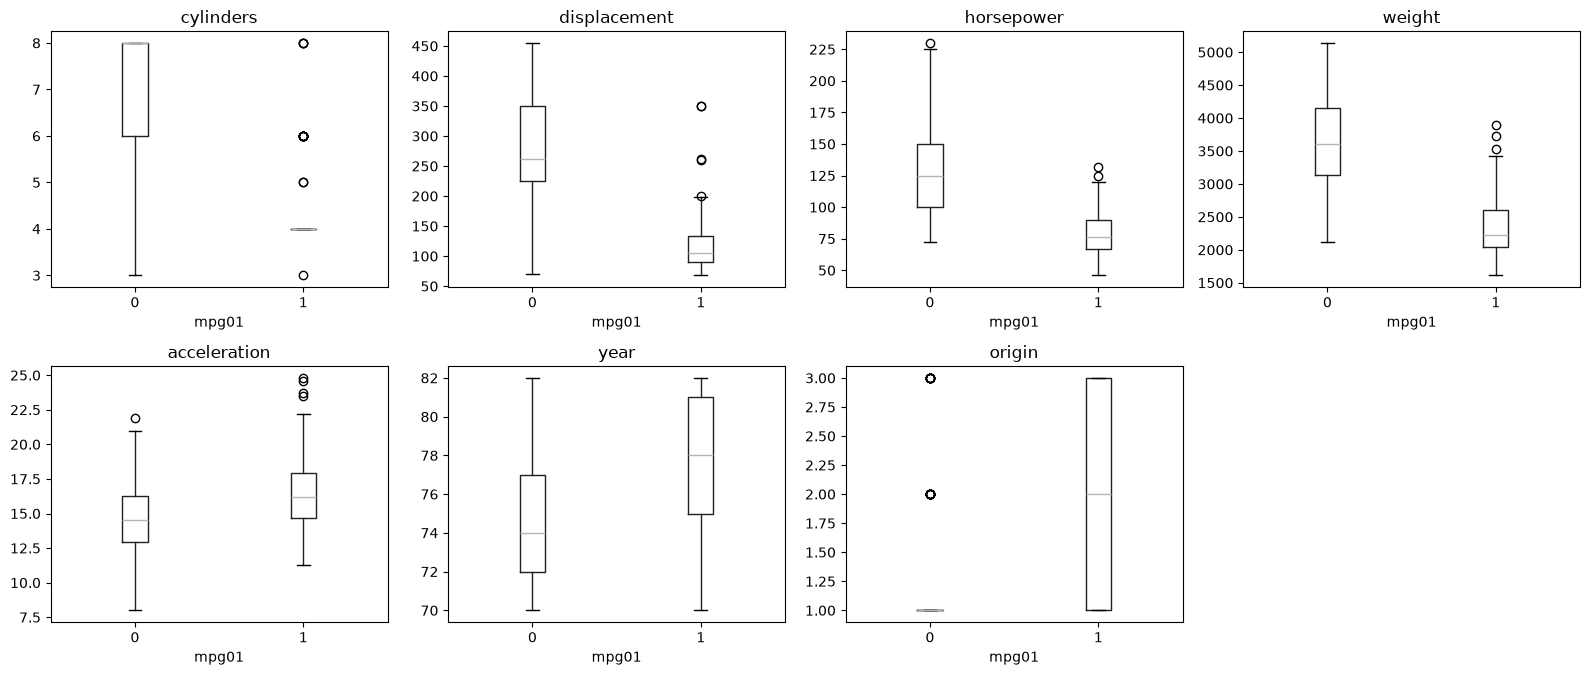

cylinders      -0.759194
weight         -0.757757
displacement   -0.753477
horsepower     -0.667053
acceleration    0.346822
year            0.429904
origin          0.513698
mpg01           1.000000
Name: mpg01, dtype: float64

In [25]:
Auto = load_data("Auto")
Auto["mpg01"] = Auto["mpg"].apply(lambda x: 1 if x > Auto["mpg"].median() else 0)

# numeric predictors only; drop mpg itself (mpg01 is a deterministic function of it)
predictors = Auto.select_dtypes("number").columns.drop(["mpg", "mpg01"])

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, predictors):
    Auto.boxplot(column=col, by="mpg01", ax=ax, grid=False)
    ax.set_title(col)
    ax.set_xlabel("mpg01")

# hide any unused axes
for ax in axes.flat[len(predictors):]:
    ax.set_visible(False)

fig.suptitle("")   # remove pandas' automatic "Boxplot grouped by mpg01" title
fig.tight_layout()
plt.show()
Auto[list(predictors) + ["mpg01"]].corr()["mpg01"].sort_values()

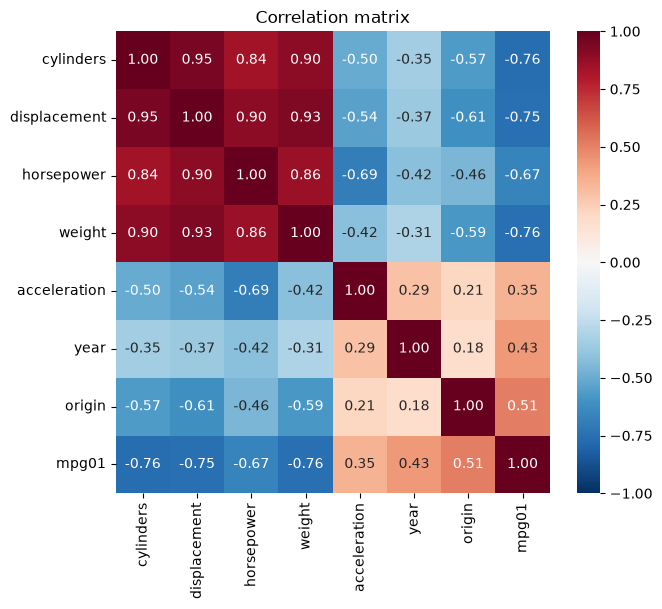

In [26]:
# Correlation matrix for checking the most associated variables
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(Auto.drop(columns=["mpg"]).corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

In [27]:
train, test = train_test_split(
    Auto, test_size=0.3, random_state=0, stratify=Auto["mpg01"]
)

predictor_sets = {
    # single strongest predictors
    "weight":              ["weight"],
    "displacement":        ["displacement"],
    "horsepower":          ["horsepower"],
    "cylinders":           ["cylinders"],

    # size/engine block (highly collinear)
    "size_engine":         ["cylinders", "displacement", "horsepower", "weight"],

    # one size proxy + orthogonal information
    "weight_year":         ["weight", "year"],
    "weight_hp_year":      ["weight", "horsepower", "year"],
    "displ_year":          ["displacement", "year"],

    # size block + year
    "size_engine_year":    ["cylinders", "displacement", "horsepower", "weight", "year"],

    # adds origin (treated as numeric here — see note below)
    "weight_year_origin":  ["weight", "year", "origin"],

    # everything except the response-defining variable
    "all":                 ["cylinders", "displacement", "horsepower", "weight",
                            "acceleration", "year", "origin"],
}

methods = {
    "Logistic": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=np.inf)),
    "LDA": LDA,
    "QDA": QDA,
    "Naive Bayes": GaussianNB,
}
for K in [1, 5, 10, 20, 50, 100]:
    methods[f"KNN, K = {K}"] = lambda K=K: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=K))

results = []
for set_name, cols in predictor_sets.items():
    for method_name, make_model in methods.items():
        model = make_model()
        model.fit(train[cols], train["mpg01"])
        results.append({
            "predictors": set_name,
            "method": method_name,
            "n_pred": len(cols),
            "test_error": 1 - model.score(test[cols], test["mpg01"]),
        })

results = pd.DataFrame(results).sort_values("test_error")
display(results.head(10).round(4))

,predictors,method,n_pred,test_error
75,displ_year,"KNN, K = 5",2,0.0763
70,displ_year,Logistic,2,0.0847
45,size_engine,"KNN, K = 5",4,0.0847
84,size_engine_year,"KNN, K = 1",5,0.0847
74,displ_year,"KNN, K = 1",2,0.0932
65,weight_hp_year,"KNN, K = 5",3,0.1017
73,displ_year,Naive Bayes,2,0.1017
57,weight_year,"KNN, K = 20",2,0.1017
56,weight_year,"KNN, K = 10",2,0.1017
44,size_engine,"KNN, K = 1",4,0.1017


For this data, we get the best performance with K = 5 and using displacement and years as predictors